## Se usa el siguiente dataset https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE171524

In [3]:
pip install scanpy

Note: you may need to restart the kernel to use updated packages.


In [4]:
import scanpy as sc

In [5]:
## es transpueto para poder posicionar bien las columnas vs variables
datos = sc.read_csv("/home/alexxus/Documents/Documentos/Documentos/ML/rna_datos/GSM5226574_C51ctr_raw_counts.csv.gz").T

In [6]:
datos

AnnData object with n_obs × n_vars = 6099 × 34546
    layers: None (.X)

In [7]:
datos.obs

""
TAGGTACCATGGCCAC-1_1
ATTCACTGTAACAGGC-1_1
TAACTTCCAACCACGC-1_1
TTGGGTACACGACAAG-1_1
AGGCCACAGAGTCACG-1_1
...
CGCCATTGTTTGCCGG-1_1
CACTGGGGTCTACGTA-1_1
CATACTTGTAGAGGAA-1_1
TTTGGTTTCCACGGAC-1_1


In [8]:
## este nos regresa las variables para los datos
datos.var

""
AL627309.1
AL627309.5
AL627309.4
AL669831.2
LINC01409
...
VN1R2
AL031676.1
SMIM34A
AL050402.1


In [9]:
datos.X.shape

(6099, 34546)

## Tamanio del genoma

In [10]:
pip install scvi-tools

Note: you may need to restart the kernel to use updated packages.


In [11]:
import scvi

In [12]:
## se establece un tamanio minimo y maxio de los genes
sc.pp.filter_genes(datos, min_cells=10)

sc.pp.highly_variable_genes(datos,n_top_genes=2000, subset=True, flavor='seurat_v3')

In [13]:
datos

AnnData object with n_obs × n_vars = 6099 × 2000
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X)

In [14]:
## entenamieto del modelo
scvi.model.SCVI.setup_anndata(datos)
variables = scvi.model.SCVI(datos)
variables.train()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


## Para ello se buscan los doublets de la secuencia y se elimninan, porque son 2 o mas secuencias que se unen por error

In [15]:
soloSecuencias = scvi.external.SOLO.from_scvi_model(variables)
soloSecuencias.train()

INFO     Creating doublets, preparing SOLO model.                                                                  


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/lightning/pytorch/trainer/conne

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.273. Signaling Trainer to stop.


In [17]:
## determina la prediccion de los valors
soloSecuencias.predict()

/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


,doublet,singlet
TAGGTACCATGGCCAC-1_1,0.814826,0.185174
ATTCACTGTAACAGGC-1_1,0.826365,0.173635
TAACTTCCAACCACGC-1_1,0.776805,0.223195
TTGGGTACACGACAAG-1_1,0.822059,0.177941
AGGCCACAGAGTCACG-1_1,0.742484,0.257516
...,...,...
CGCCATTGTTTGCCGG-1_1,0.030827,0.969173
CACTGGGGTCTACGTA-1_1,0.001330,0.998670
CATACTTGTAGAGGAA-1_1,0.009035,0.990965
TTTGGTTTCCACGGAC-1_1,0.004538,0.995462


In [68]:
df = soloSecuencias.predict()


df["prediccion"] = soloSecuencias.predict(soft =False)

#df.index = df.index.map(lambda x: x[:-2])

df

/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


,doublet,singlet,prediccion
TAGGTACCATGGCCAC-1_1,0.814826,0.185174,doublet
ATTCACTGTAACAGGC-1_1,0.826365,0.173635,doublet
TAACTTCCAACCACGC-1_1,0.776805,0.223195,doublet
TTGGGTACACGACAAG-1_1,0.822059,0.177941,doublet
AGGCCACAGAGTCACG-1_1,0.742484,0.257516,doublet
...,...,...,...
CGCCATTGTTTGCCGG-1_1,0.030827,0.969173,singlet
CACTGGGGTCTACGTA-1_1,0.001330,0.998670,singlet
CATACTTGTAGAGGAA-1_1,0.009035,0.990965,singlet
TTTGGTTTCCACGGAC-1_1,0.004538,0.995462,singlet


In [69]:
df.groupby("prediccion").count()

,doublet,singlet
prediccion,,
doublet,1013,1013
singlet,5086,5086


In [70]:
## para ver que tanta diferncia hay entre las secuencias 

df['diferemcia'] =df.doublet - df.singlet
df

,doublet,singlet,prediccion,diferemcia
TAGGTACCATGGCCAC-1_1,0.814826,0.185174,doublet,0.629653
ATTCACTGTAACAGGC-1_1,0.826365,0.173635,doublet,0.652731
TAACTTCCAACCACGC-1_1,0.776805,0.223195,doublet,0.553610
TTGGGTACACGACAAG-1_1,0.822059,0.177941,doublet,0.644119
AGGCCACAGAGTCACG-1_1,0.742484,0.257516,doublet,0.484968
...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,0.030827,0.969173,singlet,-0.938347
CACTGGGGTCTACGTA-1_1,0.001330,0.998670,singlet,-0.997341
CATACTTGTAGAGGAA-1_1,0.009035,0.990965,singlet,-0.981930
TTTGGTTTCCACGGAC-1_1,0.004538,0.995462,singlet,-0.990924


In [71]:
import seaborn as sns
import pandas as pd

In [72]:
df["diferemcia"] = pd.to_numeric(df['diferemcia'])

In [73]:
df.sort_values(by="diferemcia", ascending=False)

,doublet,singlet,prediccion,diferemcia
GACATCAAGGGCCCTT-1_1,9.956807e-01,0.004319,doublet,0.991361
GGTCACGTCTCTGCTG-1_1,9.928063e-01,0.007194,doublet,0.985613
TGGTAGTGTTCAGCGC-1_1,9.920046e-01,0.007995,doublet,0.984009
CACAGGCCAATACCTG-1_1,9.897217e-01,0.010278,doublet,0.979443
GTGACGCTCGCGGTAC-1_1,9.865913e-01,0.013409,doublet,0.973183
...,...,...,...,...
GAGTTACTCTTGCAAG-1_1,6.468832e-07,0.999999,singlet,-0.999999
CGAAGGACACGCGCAT-1_1,5.551039e-07,0.999999,singlet,-0.999999
TCATTACTCAGCTGAT-1_1,3.318046e-07,1.000000,singlet,-0.999999
TCCTCTTTCGGTAGAG-1_1,1.053152e-08,1.000000,singlet,-1.000000


<Axes: xlabel='diferemcia', ylabel='Count'>

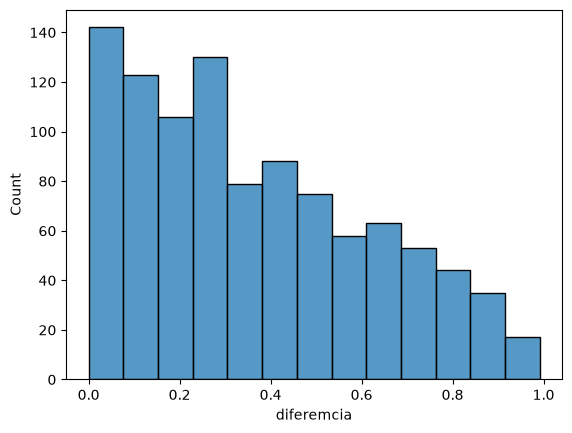

In [74]:
sns.histplot(df[df.prediccion=="doublet"], x="diferemcia")

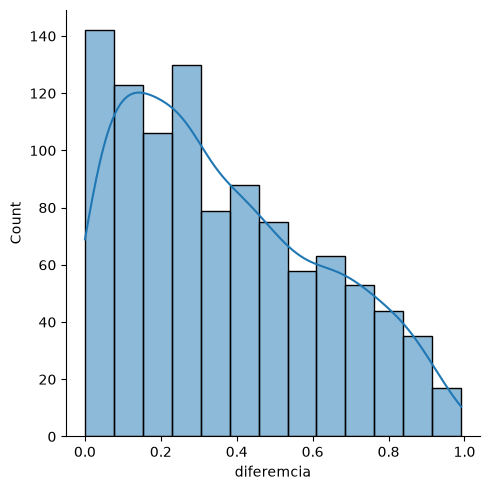

In [75]:
sns.displot(data=df[df.prediccion == "doublet"], x="diferemcia", kde=True)

### Maneja un histograma general hasta 1, no hay diferencias mayores a este numero, se podria tomar esos doublets sin problema, pero vamos a quitar los que esten por encima de 95

In [76]:
doubles_95 = df[(df.prediccion == "doublet") & (df['diferemcia']>=0.95)]
doubles_95

,doublet,singlet,prediccion,diferemcia
GACAGCCCAGGTCCGT-1_1,0.984731,0.015269,doublet,0.969461
GACATCAAGGGCCCTT-1_1,0.995681,0.004319,doublet,0.991361
GTGACGCTCGCGGTAC-1_1,0.986591,0.013409,doublet,0.973183
GGTCACGTCTCTGCTG-1_1,0.992806,0.007194,doublet,0.985613
AGATCCAGTTAGTTCG-1_1,0.986271,0.013729,doublet,0.972542
CACAGGCCAATACCTG-1_1,0.989722,0.010278,doublet,0.979443
TGGTAGTGTTCAGCGC-1_1,0.992005,0.007995,doublet,0.984009


In [77]:
doubles_95.index

Index(['GACAGCCCAGGTCCGT-1_1', 'GACATCAAGGGCCCTT-1_1', 'GTGACGCTCGCGGTAC-1_1',
       'GGTCACGTCTCTGCTG-1_1', 'AGATCCAGTTAGTTCG-1_1', 'CACAGGCCAATACCTG-1_1',
       'TGGTAGTGTTCAGCGC-1_1'],
      dtype='str')

In [78]:
print(datos_original.obs.index.dtype)
print(doubles_95.index.dtype)

str
str


In [86]:
datos_original = sc.read_csv("/home/alexxus/Documents/Documentos/Documentos/ML/rna_datos/GSM5226574_C51ctr_raw_counts.csv.gz").T


In [87]:
datos_original.obs["doublet"] = datos_original.obs.index.isin(doubles_95.index)

In [88]:
datos_original.obs["doublet"] = datos_original.obs.index.astype(str).isin(doubles_95.index.astype(str))

In [89]:
datos_original.obs

,doublet
TAGGTACCATGGCCAC-1_1,False
ATTCACTGTAACAGGC-1_1,False
TAACTTCCAACCACGC-1_1,False
TTGGGTACACGACAAG-1_1,False
AGGCCACAGAGTCACG-1_1,False
...,...
CGCCATTGTTTGCCGG-1_1,False
CACTGGGGTCTACGTA-1_1,False
CATACTTGTAGAGGAA-1_1,False
TTTGGTTTCCACGGAC-1_1,False


In [90]:
datos_original.obs.doublet.value_counts()

doublet
False    6092
True        7
Name: count, dtype: int64

In [91]:
datos_original = datos_original[~datos_original.obs.doublet]

In [92]:
datos_original

View of AnnData object with n_obs × n_vars = 6092 × 34546
    obs: 'doublet'
    layers: None (.X)

## Procesamiento de genes

### Genes mitocondriales

In [96]:
datos_original.var['mt']=datos_original.var.index.str.startswith('MT-')

/tmp/ipykernel_4173/2388295681.py:1: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  datos_original.var['mt']=datos_original.var.index.str.startswith('MT-')


In [99]:
datos_original.var

,mt
AL627309.1,False
AL627309.5,False
AL627309.4,False
AL669831.2,False
LINC01409,False
...,...
VN1R2,False
AL031676.1,False
SMIM34A,False
AL050402.1,False


In [100]:
ribosoma = "http://software.broadinstitute.org/gsea/msigdb/download_geneset.jsp?geneSetName=KEGG_RIBOSOME&fileType=txt"

In [101]:
ribosoma_genes = pd.read_table(ribosoma, skiprows=2, header=None)

In [102]:
ribosoma_genes

,0
0,FAU
1,MRPL13
2,RPL10
3,RPL10A
4,RPL10L
...,...
83,RPS9
84,RPSA
85,RSL24D1
86,RSL24D1P11


In [104]:
ribosoma_genes[0].values

<StringArray>
[       'FAU',     'MRPL13',      'RPL10',     'RPL10A',     'RPL10L',
      'RPL11',      'RPL12',      'RPL13',     'RPL13A',      'RPL14',
      'RPL15',      'RPL17',      'RPL18',     'RPL18A',      'RPL19',
      'RPL21',      'RPL22',    'RPL22L1',      'RPL23',     'RPL23A',
      'RPL24',      'RPL26',    'RPL26L1',      'RPL27',     'RPL27A',
      'RPL28',      'RPL29',       'RPL3',      'RPL30',      'RPL31',
      'RPL32',      'RPL34',      'RPL35',     'RPL35A',      'RPL36',
     'RPL36A',    'RPL36AL',      'RPL37',     'RPL37A',      'RPL38',
      'RPL39',      'RPL3L',       'RPL4',      'RPL41',       'RPL5',
       'RPL6',       'RPL7',      'RPL7A',       'RPL8',       'RPL9',
      'RPLP0',      'RPLP1',      'RPLP2',      'RPS10',      'RPS11',
      'RPS12',      'RPS13',      'RPS15',     'RPS15A',      'RPS16',
      'RPS17',      'RPS18',      'RPS19',       'RPS2',      'RPS20',
      'RPS21',      'RPS23',      'RPS24',      'RPS25',      '

In [105]:
datos_original.var['ribosoma']=datos_original.var_names.isin(ribosoma_genes[0].values)


In [106]:
datos_original.var

,mt,ribosoma
AL627309.1,False,False
AL627309.5,False,False
AL627309.4,False,False
AL669831.2,False,False
LINC01409,False,False
...,...,...
VN1R2,False,False
AL031676.1,False,False
SMIM34A,False,False
AL050402.1,False,False


In [107]:
sc.pp.calculate_qc_metrics(datos_original, qc_vars=['mt', 'ribosoma'], percent_top=None, log1p=False, inplace=True)

In [109]:
datos_original.var

,mt,ribosoma,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
AL627309.1,False,False,8,0.001313,99.868680,8.0
AL627309.5,False,False,33,0.005417,99.458306,33.0
AL627309.4,False,False,4,0.000657,99.934340,4.0
AL669831.2,False,False,2,0.000328,99.967170,2.0
LINC01409,False,False,273,0.048588,95.518713,296.0
...,...,...,...,...,...,...
VN1R2,False,False,0,0.000000,100.000000,0.0
AL031676.1,False,False,0,0.000000,100.000000,0.0
SMIM34A,False,False,0,0.000000,100.000000,0.0
AL050402.1,False,False,0,0.000000,100.000000,0.0


In [110]:
datos_original.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribosoma,pct_counts_ribosoma
TAGGTACCATGGCCAC-1_1,False,6764,24256.0,153.0,0.630772,55.0,0.226748
ATTCACTGTAACAGGC-1_1,False,6686,19020.0,404.0,2.124080,115.0,0.604627
TAACTTCCAACCACGC-1_1,False,5158,15645.0,221.0,1.412592,211.0,1.348674
TTGGGTACACGACAAG-1_1,False,4900,15220.0,3.0,0.019711,5.0,0.032852
AGGCCACAGAGTCACG-1_1,False,5544,13217.0,417.0,3.155028,82.0,0.620413
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


In [111]:
## se analiza la cantiadad de genes que no tienen ni una celula
datos_original.var.sort_values('n_cells_by_counts')

,mt,ribosoma,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
AC025183.2,False,False,0,0.000000,100.000000,0.0
AC010387.2,False,False,0,0.000000,100.000000,0.0
AC136428.1,False,False,0,0.000000,100.000000,0.0
AL645608.2,False,False,0,0.000000,100.000000,0.0
PERM1,False,False,0,0.000000,100.000000,0.0
...,...,...,...,...,...,...
AKAP13,False,False,4453,3.051543,26.904137,18590.0
NEAT1,False,False,4539,5.316481,25.492449,32388.0
MBNL1,False,False,4547,2.872948,25.361129,17502.0
ZBTB20,False,False,4693,2.597669,22.964544,15825.0


In [112]:
## asis se determina una cantidad minima
sc.pp.filter_genes(datos_original, min_cells=3)
datos_original.var.sort_values("n_cells_by_counts")

,mt,ribosoma,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells
AC011467.1,False,False,3,0.000492,99.950755,3.0,3
HAPLN4,False,False,3,0.000492,99.950755,3.0,3
TSSK6,False,False,3,0.000492,99.950755,3.0,3
CCL26,False,False,3,0.000492,99.950755,3.0,3
ZNF735,False,False,3,0.000492,99.950755,3.0,3
...,...,...,...,...,...,...,...
AKAP13,False,False,4453,3.051543,26.904137,18590.0,4453
NEAT1,False,False,4539,5.316481,25.492449,32388.0,4539
MBNL1,False,False,4547,2.872948,25.361129,17502.0,4547
ZBTB20,False,False,4693,2.597669,22.964544,15825.0,4693


In [129]:
import matplotlib.pyplot as plt
import numpy as np

<function matplotlib.pyplot.show(close=None, block=None)>

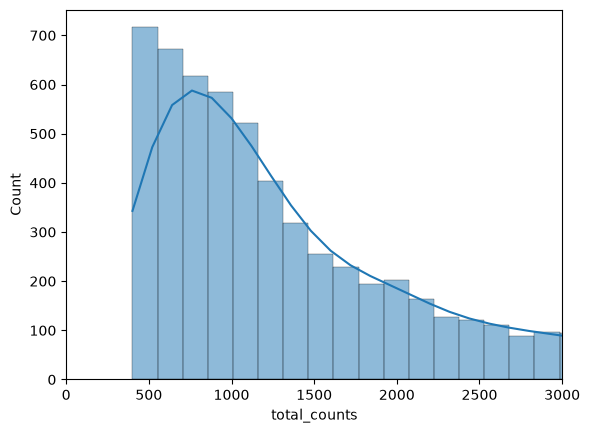

In [124]:
## para las observaciones
sns.histplot(data=datos_original.obs, x="total_counts", kde=True)



plt.xlim(0, 3000)
plt.show

<Axes: xlabel='total_counts'>

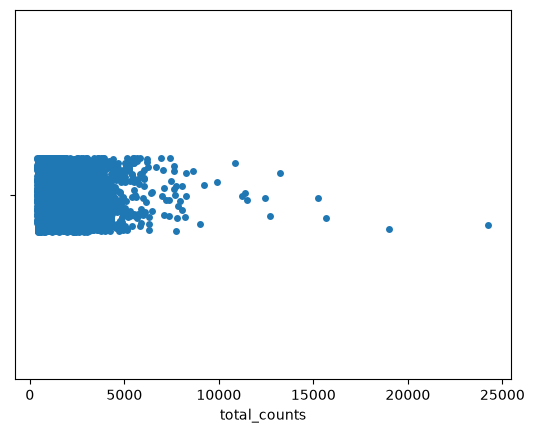

In [121]:
sns.stripplot(data=datos_original.obs, x="total_counts")

## DOnde nos podemos percatar de una gran cantidad de valores con cantidades por 400 - 800 que generarn ruido asi que es mejor eliminarlo

In [125]:
## vista de violin para los outliners

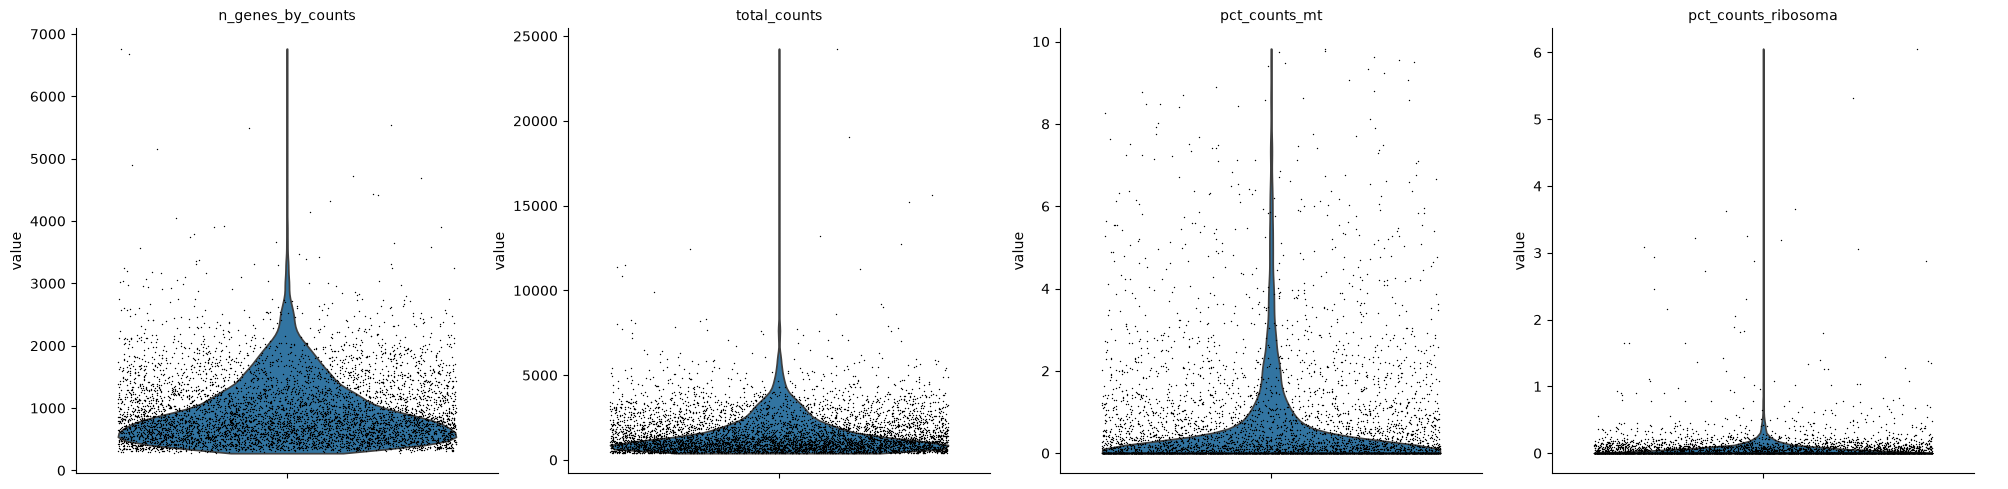

In [128]:
sc.pl.violin(datos_original, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribosoma'], 
             jitter=0.4, multi_panel=True)

In [130]:
## en la primra grafica de numero de genes hay una gran cantidad de outlines, asi que se definie un percentil para ello
cota_superior = np.quantile(datos_original.obs.n_genes_by_counts.values, .90)

In [131]:
cota_superior

np.float64(1714.9000000000005)

In [133]:
datos_original = datos_original[datos_original.obs.n_genes_by_counts < cota_superior]
datos_original.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribosoma,pct_counts_ribosoma
GCCAGGTGTTGTCCCT-1_1,False,1670,3578.0,28.0,0.782560,2.0,0.055897
ACTTCCGTCCTTGGAA-1_1,False,1700,3571.0,34.0,0.952114,2.0,0.056007
CCTCACAGTATCCCTC-1_1,False,1704,3510.0,0.0,0.000000,2.0,0.056980
GCTGCAGAGGTCCCTG-1_1,False,1618,3447.0,0.0,0.000000,0.0,0.000000
GCTCAAATCTCATTAC-1_1,False,1624,3418.0,1.0,0.029257,2.0,0.058514
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


In [134]:
datos_original = datos_original[datos_original.obs.pct_counts_mt < 20]
datos_original = datos_original[datos_original.obs.pct_counts_ribosoma < 2]
datos_original

View of AnnData object with n_obs × n_vars = 5465 × 24645
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribosoma', 'pct_counts_ribosoma'
    var: 'mt', 'ribosoma', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: None (.X)

## Normalizacion

In [135]:
sc.pp.normalize_total(datos_original, target_sum=1e4)

/tmp/ipykernel_4173/1740103803.py:1: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.normalize_total(datos_original, target_sum=1e4)


In [139]:
datos_original.X.sum(axis=1)

array([10000., 10000., 10000., ..., 10000., 10000., 10000.],
      shape=(5465,), dtype=float32)

In [140]:
## SE NORMALIZA EN LOG

sc.pp.log1p(datos_original)

In [141]:
datos_original.X.sum(axis=1)


array([2750.5889 , 2769.7783 , 2801.4155 , ..., 1191.2706 , 1022.75116,
       1162.8784 ], shape=(5465,), dtype=float32)

In [142]:
datos_original.raw = datos_original

## Cluster

In [143]:
sc.pp.highly_variable_genes(datos_original, n_top_genes=2000)

In [144]:
datos_original.var

,mt,ribosoma,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm
AL627309.1,False,False,8,0.001313,99.868680,8.0,8,False,0.011799,2.722139,1.092535
AL627309.5,False,False,33,0.005417,99.458306,33.0,33,False,0.027609,2.354666,-0.087634
AL627309.4,False,False,4,0.000657,99.934340,4.0,4,False,0.002144,1.809065,-1.839873
LINC01409,False,False,273,0.048588,95.518713,296.0,273,False,0.268132,2.353027,-0.092895
FAM87B,False,False,6,0.000985,99.901510,6.0,6,False,0.007285,1.947419,-1.395538
...,...,...,...,...,...,...,...,...,...,...,...
AL354822.1,False,False,132,0.022489,97.833224,137.0,132,False,0.154760,2.432239,0.161500
AL592183.1,False,False,1001,0.198621,83.568615,1210.0,1001,False,0.882677,2.525729,-0.423485
AC240274.1,False,False,162,0.027413,97.340775,167.0,162,False,0.149930,2.329345,-0.168955
AC007325.4,False,False,4,0.000657,99.934340,4.0,4,False,0.001971,1.770639,-1.963278


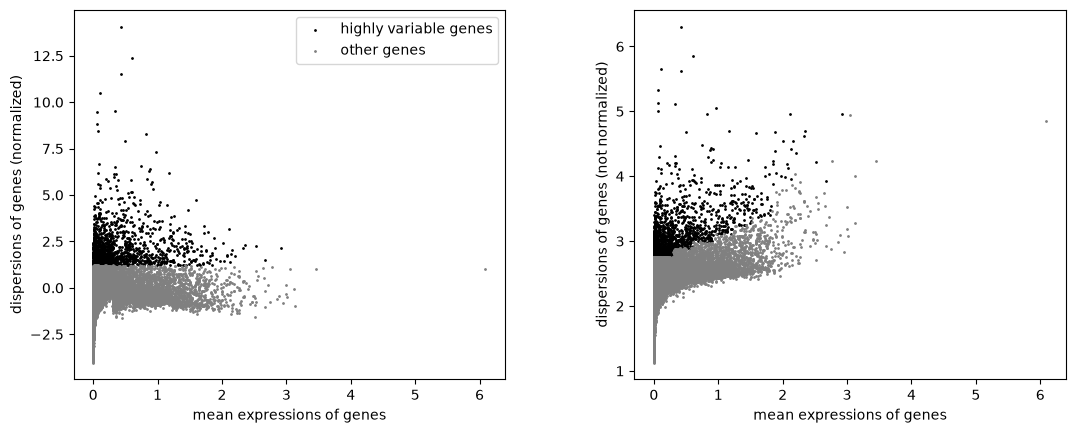

In [147]:
sc.pl.highly_variable_genes(datos_original)
## se determina a partir de una realacion de varibles, cuales son mas critcas, en base a la normalizacion y sin
#esta

In [149]:
datos_original = datos_original[:, datos_original.var.highly_variable]

In [150]:
sc.pp.regress_out(datos_original, ["total_counts", "pct_counts_mt", "pct_counts_ribosoma"])

/tmp/ipykernel_4173/526341000.py:1: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.regress_out(datos_original, ["total_counts", "pct_counts_mt", "pct_counts_ribosoma"])
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/home/alexxus/.config/jupyterlab-desktop/envs/env_1/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


In [151]:
sc.pp.scale(datos_original, max_value=10)

## Despues de esclar se usa una reduccion de dimensionalidad con PCA

In [152]:
sc.tl.pca(datos_original, svd_solver="arpack")

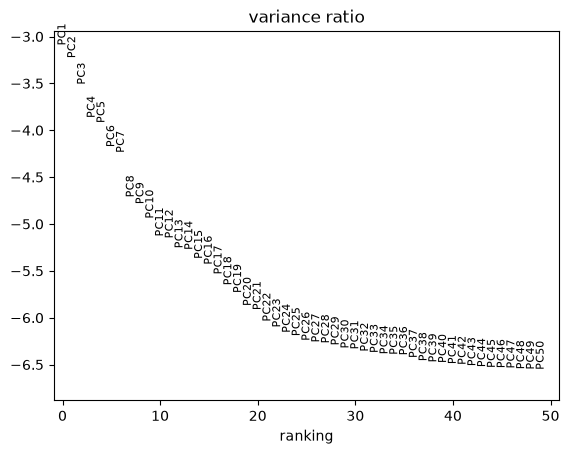

In [154]:
sc.pl.pca_variance_ratio(datos_original, log=True, n_pcs=50)

In [155]:
## con 30 ~ 35 de pca se mantiene bien la funcion, ahora probamos los vecinos
sc.pp.neighbors(datos_original, n_pcs=50)

In [156]:
## como los vecinos generan una matriz se mapea con map

sc.tl.umap(datos_original)

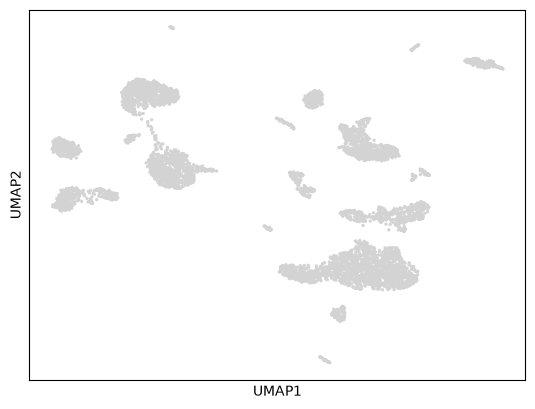

In [157]:
sc.pl.umap(datos_original)

In [160]:
pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 2.5 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 5.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]/3 [leidenalg]
Note: you may need to restart the kernel to use updated packages.


In [161]:
## para ver mejor las vecindades que genero se usa leiden
sc.tl.leiden(datos_original, resolution=0.6)

/tmp/ipykernel_4173/3365847009.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(datos_original, resolution=0.6)


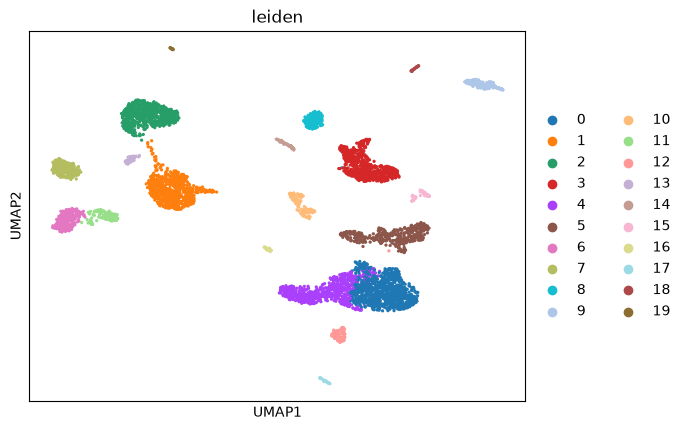

In [162]:
sc.pl.umap(datos_original, color=['leiden'])